In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
train = pd.read_csv("train.csv")

In [5]:
print("Dataset shape:", train.shape)

Dataset shape: (2930, 82)


In [6]:
display(train.head())

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   object 
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   object 
 7   Alley            198 non-null    object 
 8   Lot Shape        2930 non-null   object 
 9   Land Contour     2930 non-null   object 
 10  Utilities        2930 non-null   object 
 11  Lot Config       2930 non-null   object 
 12  Land Slope       2930 non-null   object 
 13  Neighborhood     2930 non-null   object 
 14  Condition 1      2930 non-null   object 
 15  Condition 2      2930 non-null   object 
 16  Bldg Type        2930 non-null   object 
 17  House Style   

In [8]:
print("Rows and columns:", train.shape)
print("Duplicate rows:", train.duplicated().sum())

Rows and columns: (2930, 82)
Duplicate rows: 0


In [9]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

In [10]:
display(missing.to_frame("Missing_Count"))
display(train.describe().T)

,Missing_Count
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Cond,159
Garage Qual,159
Garage Finish,159


,count,mean,std,min,25%,50%,75%,max
Order,2930.0,1.465500e+03,8.459625e+02,1.0,7.332500e+02,1465.5,2.197750e+03,2.930000e+03
PID,2930.0,7.144645e+08,1.887308e+08,526301100.0,5.284770e+08,535453620.0,9.071811e+08,1.007100e+09
MS SubClass,2930.0,5.738737e+01,4.263802e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2440.0,6.922459e+01,2.336533e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2930.0,1.014792e+04,7.880018e+03,1300.0,7.440250e+03,9436.5,1.155525e+04,2.152450e+05
Overall Qual,2930.0,6.094881e+00,1.411026e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2930.0,5.563140e+00,1.111537e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2930.0,1.971356e+03,3.024536e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2930.0,1.984267e+03,2.086029e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2907.0,1.018968e+02,1.791126e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03


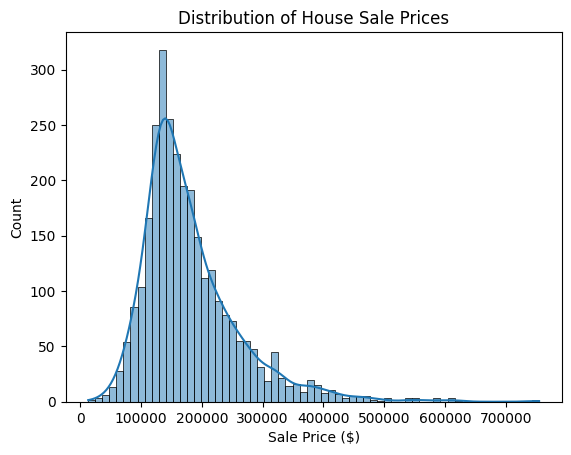

In [12]:
sns.histplot(train["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.show()

In [14]:
print(train.columns.tolist())

['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street', 'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars', 'Garage Area', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Wood Deck 

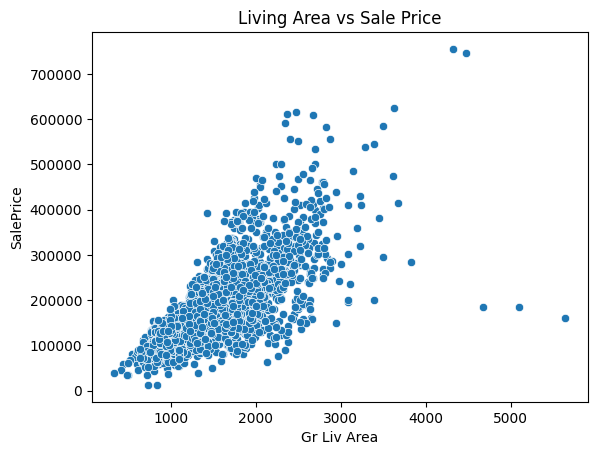

In [18]:
sns.scatterplot(
    data=train,
    x="Gr Liv Area",
    y="SalePrice"
)
plt.title("Living Area vs Sale Price")
plt.show()

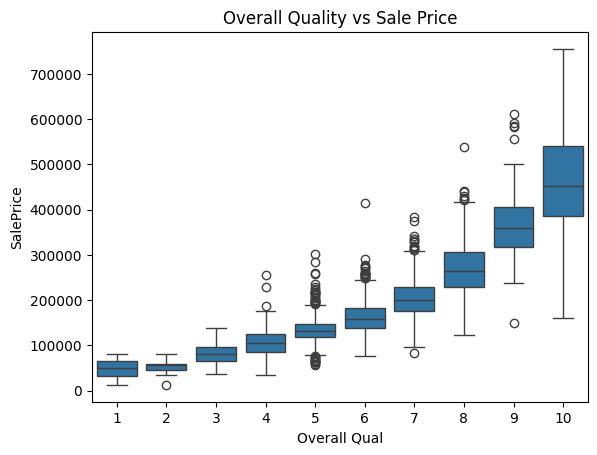

In [19]:
sns.boxplot(
    data=train,
    x="Overall Qual",
    y="SalePrice"
)
plt.title("Overall Quality vs Sale Price")
plt.show()

In [20]:
numeric = train.select_dtypes(include=np.number)

correlation = numeric.corr()["SalePrice"]
print(correlation.sort_values(ascending=False).head(15))

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Mas Vnr Area      0.508285
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432914
Name: SalePrice, dtype: float64


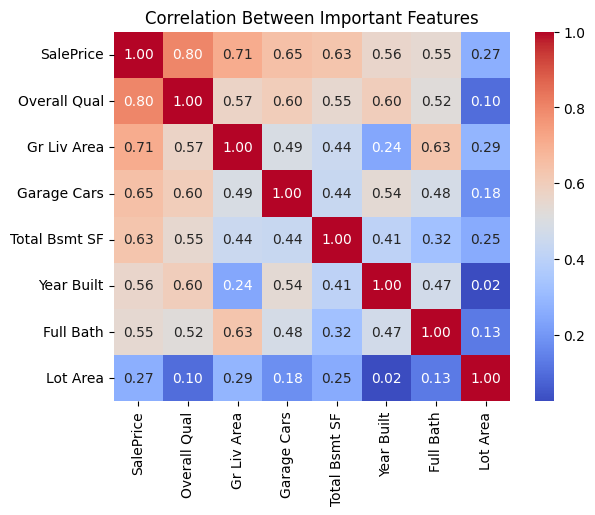

In [23]:
features = [
    "SalePrice", "Overall Qual", "Gr Liv Area",
    "Garage Cars", "Total Bsmt SF", "Year Built",
    "Full Bath", "Lot Area"
]

sns.heatmap(
    train[features].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Important Features")
plt.show()

In [24]:
def add_features(df):
    df = df.copy()

    df["House Age"] = (
        df["Yr Sold"] - df["Year Built"]
    ).clip(lower=0)

    df["Years Since Remodel"] = (
        df["Yr Sold"] - df["Year Remod Add"]
    ).clip(lower=0)

    df["Total Bathrooms"] = (
        df["Full Bath"]
        + 0.5 * df["Half Bath"]
        + df["Bsmt Full Bath"]
        + 0.5 * df["Bsmt Half Bath"]
    )

    df["Total PorchSF"] = (
        df["Wood DeckSF"]
        + df["Open PorchSF"]
        + df["Enclosed Porch"]
        + df["3Ssn Porch"]
        + df["Screen Porch"]
    )

    return df

In [26]:
for col in train.columns:
    if "Year" in col or "Remod" in col:
        print(repr(col))

'Year Built'
'Year Remod/Add'


In [27]:
def add_features(df):
    df = df.copy()

    # Normalize column names for feature engineering
    column_map = {
        col: col.replace(" ", "").replace("_", "")
        for col in df.columns
    }

    df = df.rename(columns=column_map)

    # Create House Age
    if {"YrSold", "YearBuilt"}.issubset(df.columns):
        df["HouseAge"] = (
            df["YrSold"] - df["YearBuilt"]
        ).clip(lower=0)

    # Create Years Since Remodel
    if {"YrSold", "YearRemodAdd"}.issubset(df.columns):
        df["YearsSinceRemodel"] = (
            df["YrSold"] - df["YearRemodAdd"]
        ).clip(lower=0)

    # Create Total Bathrooms
    bathroom_cols = [
        "FullBath", "HalfBath",
        "BsmtFullBath", "BsmtHalfBath"
    ]

    if all(col in df.columns for col in bathroom_cols):
        df["TotalBathrooms"] = (
            df["FullBath"]
            + 0.5 * df["HalfBath"]
            + df["BsmtFullBath"]
            + 0.5 * df["BsmtHalfBath"]
        )

    # Create Total Porch Area
    porch_cols = [
        "WoodDeckSF", "OpenPorchSF",
        "EnclosedPorch", "3SsnPorch",
        "ScreenPorch"
    ]

    if all(col in df.columns for col in porch_cols):
        df["TotalPorchSF"] = df[porch_cols].sum(axis=1)

    return df

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
import numpy as np

df = add_features(train)

X = df.drop(columns=["SalePrice", "Id"], errors="ignore")
y = df["SalePrice"]

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Preprocessing setup completed successfully!")

Training data: (2344, 84)
Testing data: (586, 84)
Preprocessing setup completed successfully!


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
}

results = []
fitted_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    fitted_models[name] = pipeline

comparison = pd.DataFrame(results).sort_values("RMSE")
display(comparison.round(3))

,Model,MAE,RMSE,R2
2,Extra Trees,15871.080,26844.365,0.910
1,Random Forest,16020.482,26902.176,0.910
3,Gradient Boosting,16255.656,27179.221,0.908
0,Linear Regression,15985.711,29492.715,0.892


Best model by test RMSE: Extra Trees


,Feature,Importance
182,categorical__ExterQual_TA,0.220897
5,numeric__OverallQual,0.195569
27,numeric__GarageCars,0.129742
17,numeric__GrLivArea,0.057380
194,categorical__BsmtQual_Ex,0.054699
238,categorical__KitchenQual_Ex,0.030325
39,numeric__TotalBathrooms,0.026255
25,numeric__Fireplaces,0.020694
14,numeric__1stFlrSF,0.019771
20,numeric__FullBath,0.017576


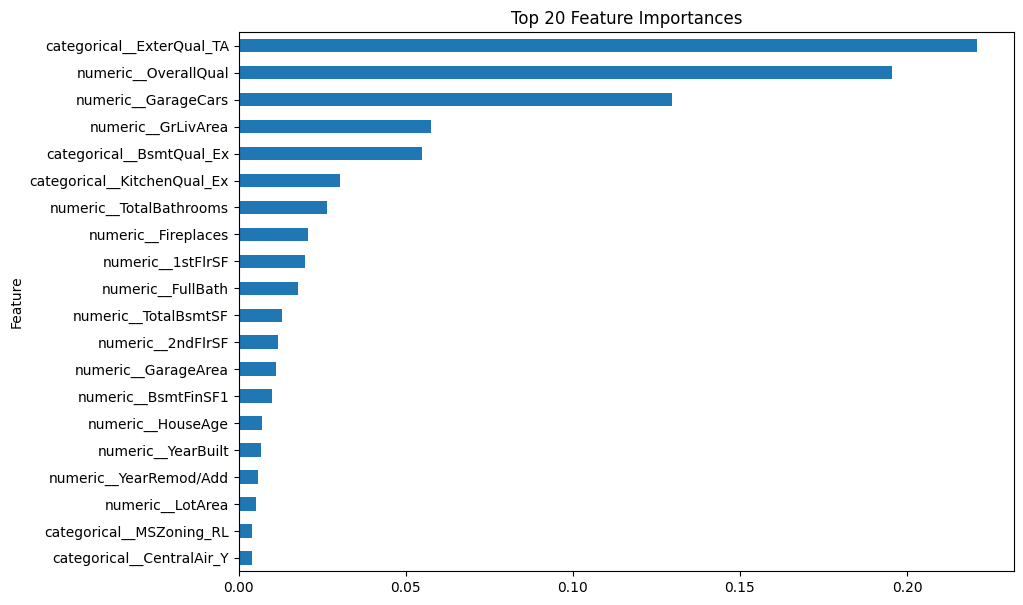

In [30]:
best_name = comparison.iloc[0]["Model"]
best_model = fitted_models[best_name]

print("Best model by test RMSE:", best_name)

if hasattr(best_model.named_steps["model"], "feature_importances_"):
    importances = best_model.named_steps[
        "model"
    ].feature_importances_

    feature_names = best_model.named_steps[
        "preprocessor"
    ].get_feature_names_out()

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(20))

    importance_df.head(20).sort_values(
        "Importance"
    ).plot(
        x="Feature",
        y="Importance",
        kind="barh",
        legend=False,
        figsize=(10, 7)
    )
    plt.title("Top 20 Feature Importances")
    plt.show()

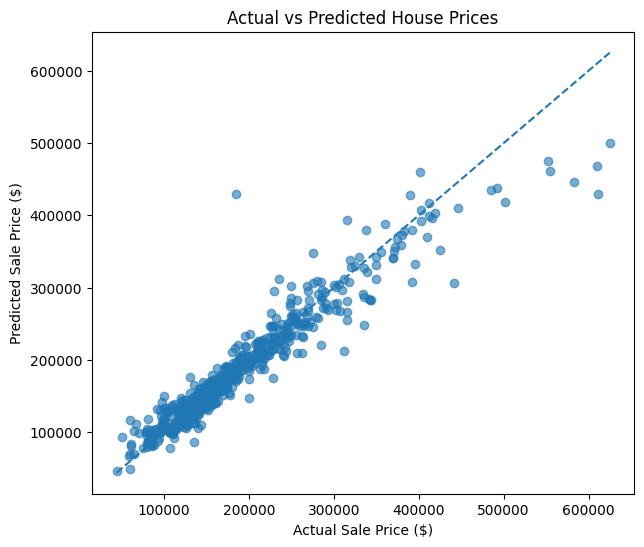

In [31]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.6)

lower = min(y_test.min(), best_predictions.min())
upper = max(y_test.max(), best_predictions.max())

plt.plot([lower, upper], [lower, upper], "--")
plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title("Actual vs Predicted House Prices")
plt.show()

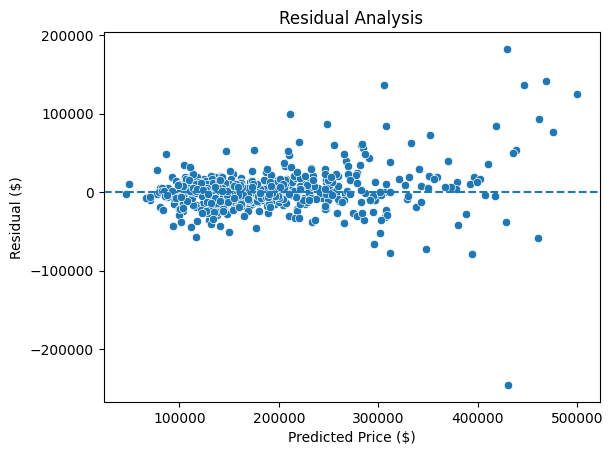

In [32]:
residuals = y_test - best_predictions

sns.scatterplot(
    x=best_predictions,
    y=residuals
)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Price ($)")
plt.ylabel("Residual ($)")
plt.title("Residual Analysis")
plt.show()

In [33]:
import joblib

joblib.dump(best_model, "house_price_model.pkl")
print("Model saved successfully")

Model saved successfully


In [35]:
model = joblib.load("house_price_model.pkl")

In [36]:
new_house = X_test.iloc[[0]].copy()

predicted_price = model.predict(new_house)[0]

print(f"Predicted house price: ${predicted_price:,.2f}")

Predicted house price: $159,952.66
